In [1]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

candidates = [
    Path("wyniki_walidacji_lppls_04/lppls_daily_validation.csv"),
    Path("lppls_daily_validation.csv")
]

input_csv = next(
    (p for p in candidates if p.exists()),
    None
)

if input_csv is None:
    raise FileNotFoundError(
        "Nie znaleziono pliku lppls_daily_validation.csv"
    )

daily = pd.read_csv(input_csv)

# Obsługa dwóch nazw kolumny daty
if "date" not in daily.columns and "win_end" in daily.columns:
    daily = daily.rename(columns={"win_end": "date"})

required = {"date", "confidence", "literature_bubble"}

missing = required - set(daily.columns)

if missing:
    raise ValueError(f"Brak kolumn: {missing}")

daily["date"] = pd.to_datetime(daily["date"]).dt.normalize()
daily["confidence"] = pd.to_numeric(daily["confidence"])
daily["literature_bubble"] = pd.to_numeric(
    daily["literature_bubble"]
).astype(int)

daily = daily.sort_values("date").reset_index(drop=True)

assert daily["date"].is_unique
assert daily["confidence"].between(0, 1).all()
assert daily["literature_bubble"].isin([0, 1]).all()

# ==========================================
# 2. Konfiguracja eksperymentu
# ==========================================

THRESHOLDS = [0.00, 0.02, 0.05, 0.10, 0.15, 0.20]

PREWARNING_DAYS = 30

OUTPUT = Path("wyniki_progi_lppls_05")
OUTPUT.mkdir(parents=True, exist_ok=True)

print("Liczba analizowanych dni:", len(daily))
print("Początek:", daily["date"].min())
print("Koniec:", daily["date"].max())
print("Dni oznaczone jako bańka:",
      daily["literature_bubble"].sum())

display(daily.head())


Liczba analizowanych dni: 3624
Początek: 2015-01-30 00:00:00
Koniec: 2024-12-31 00:00:00
Dni oznaczone jako bańka: 868


,date,n_all,n_accepted,literature_bubble,confidence,lppls_alarm
0,2015-01-30,1,0,0,0.0,0
1,2015-01-31,1,0,0,0.0,0
2,2015-02-01,1,0,0,0.0,0
3,2015-02-02,1,0,0,0.0,0
4,2015-02-03,1,0,0,0.0,0


In [2]:

data_union = [
    ["UNION01", "2016-06-08", "2016-06-18"],
    ["UNION02", "2016-12-30", "2017-01-15"],
    ["UNION03", "2017-02-22", "2017-03-07"],
    ["UNION04", "2017-04-27", "2017-07-05"],
    ["UNION05", "2017-07-15", "2018-01-09"],
    ["UNION06", "2019-06-17", "2019-07-13"],
    ["UNION07", "2019-08-09", "2019-08-10"],
    ["UNION08", "2019-12-06", "2020-01-05"],
    ["UNION09", "2020-02-07", "2020-02-17"],
    ["UNION10", "2020-03-20", "2020-09-21"],
    ["UNION11", "2020-11-06", "2021-05-20"],
    ["UNION12", "2021-08-08", "2021-09-19"],
    ["UNION13", "2021-10-05", "2021-12-02"],
    ["UNION14", "2024-03-04", "2024-03-25"],
]

episodes = pd.DataFrame(
    data_union,
    columns=["bubble_id", "start", "end"]
)

episodes["start"] = pd.to_datetime(episodes["start"])
episodes["end"] = pd.to_datetime(episodes["end"])

# Sprawdzenie zgodności etykiet
reference_labels = np.zeros(len(daily), dtype=int)

for ep in episodes.itertuples(index=False):
    reference_labels |= daily["date"].between(
        ep.start, ep.end
    ).to_numpy(dtype=int)

mismatches = (
    reference_labels != daily["literature_bubble"].to_numpy()
).sum()

print("Niezgodności etykiet:", mismatches)

if mismatches:
    raise ValueError(
        "Etykiety dzienne nie zgadzają się z okresami UNION."
    )

display(episodes)


Niezgodności etykiet: 0


,bubble_id,start,end
0,UNION01,2016-06-08,2016-06-18
1,UNION02,2016-12-30,2017-01-15
2,UNION03,2017-02-22,2017-03-07
3,UNION04,2017-04-27,2017-07-05
4,UNION05,2017-07-15,2018-01-09
5,UNION06,2019-06-17,2019-07-13
6,UNION07,2019-08-09,2019-08-10
7,UNION08,2019-12-06,2020-01-05
8,UNION09,2020-02-07,2020-02-17
9,UNION10,2020-03-20,2020-09-21


In [3]:

daily_results = []
threshold_signals = {}

y_true = daily["literature_bubble"].to_numpy()

for threshold in THRESHOLDS:

    y_pred = (
        daily["confidence"].to_numpy() > threshold
    ).astype(int)

    threshold_signals[threshold] = y_pred

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    precision = precision_score(
        y_true, y_pred, zero_division=0
    )

    recall = recall_score(
        y_true, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_true, y_pred, zero_division=0
    )

    specificity = tn / (tn + fp) if tn + fp > 0 else np.nan

    fpr = fp / (fp + tn) if fp + tn > 0 else np.nan

    daily_results.append({
        "threshold": threshold,
        "alarm_days": int(y_pred.sum()),
        "TP": int(tp),
        "FP_days": int(fp),
        "FN": int(fn),
        "TN": int(tn),
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "specificity": specificity,
        "false_positive_rate": fpr,
        "time_in_alarm": float(y_pred.mean())
    })

summary = pd.DataFrame(daily_results)

display(summary.round(3))

summary.to_csv(
    OUTPUT / "01_progi_metryki_dzienne.csv",
    index=False
)


,threshold,alarm_days,TP,FP_days,FN,TN,precision,recall,f1,specificity,false_positive_rate,time_in_alarm
0,0.00,556,294,262,574,2494,0.529,0.339,0.413,0.905,0.095,0.153
1,0.02,556,294,262,574,2494,0.529,0.339,0.413,0.905,0.095,0.153
2,0.05,317,189,128,679,2628,0.596,0.218,0.319,0.954,0.046,0.087
3,0.10,159,105,54,763,2702,0.660,0.121,0.204,0.980,0.020,0.044
4,0.15,110,73,37,795,2719,0.664,0.084,0.149,0.987,0.013,0.030
5,0.20,43,29,14,839,2742,0.674,0.033,0.064,0.995,0.005,0.012


In [4]:

episode_results = []

for threshold, pred in threshold_signals.items():

    alerts = pd.Series(
        pred, index=daily.index
    ).eq(1)

    for ep in episodes.itertuples(index=False):

        # Dni należące do epizodu
        during = daily["date"].between(
            ep.start, ep.end
        )

        # Okres 30 dni przed epizodem,
        # z wyłączeniem innych oznaczonych baniek
        before = (
            (daily["date"] >= ep.start - pd.Timedelta(
                days=PREWARNING_DAYS
            ))
            & (daily["date"] < ep.start)
            & (daily["literature_bubble"] == 0)
        )

        # Daty alarmów wewnątrz epizodu
        in_dates = daily.loc[
            during & alerts, "date"
        ]

        # Daty alarmów przed epizodem
        pre_dates = daily.loc[
            before & alerts, "date"
        ]

        n_days = int(during.sum())
        n_alarm = len(in_dates)

        coverage = (
            n_alarm / n_days if n_days > 0 else np.nan
        )

        first_alarm = (
            in_dates.min()
            if n_alarm > 0
            else pd.NaT
        )

        nearest_pre = (
            pre_dates.max()
            if len(pre_dates) > 0
            else pd.NaT
        )

        days_before = (
            (ep.start - nearest_pre).days
            if pd.notna(nearest_pre)
            else np.nan
        )

        episode_results.append({
            "threshold": threshold,
            "bubble_id": ep.bubble_id,
            "start": ep.start.date().isoformat(),
            "end": ep.end.date().isoformat(),
            "days_in_episode": n_days,
            "alarm_days_in_episode": n_alarm,
            "coverage": coverage,
            "detected_1_day": n_alarm >= 1,
            "detected_3_days": n_alarm >= 3,
            "first_alarm_in_episode": (
                first_alarm.date().isoformat()
                if pd.notna(first_alarm) else ""
            ),
            "prewarning_30d": len(pre_dates) > 0,
            "alarm_days_before_episode": len(pre_dates),
            "nearest_prewarning_date": (
                nearest_pre.date().isoformat()
                if pd.notna(nearest_pre) else ""
            ),
            "days_before_start": days_before
        })

episode_details = pd.DataFrame(episode_results)

episode_details.to_csv(
    OUTPUT / "02_progi_14_epizodow.csv",
    index=False
)

display(episode_details.head(14))


,threshold,bubble_id,start,end,days_in_episode,alarm_days_in_episode,coverage,detected_1_day,detected_3_days,first_alarm_in_episode,prewarning_30d,alarm_days_before_episode,nearest_prewarning_date,days_before_start
0,0.0,UNION01,2016-06-08,2016-06-18,11,0,0.000000,False,False,,False,0,,NaN
1,0.0,UNION02,2016-12-30,2017-01-15,17,9,0.529412,True,True,2016-12-30,True,9,2016-12-25,5.0
2,0.0,UNION03,2017-02-22,2017-03-07,14,11,0.785714,True,True,2017-02-25,True,11,2017-02-21,1.0
3,0.0,UNION04,2017-04-27,2017-07-05,70,28,0.400000,True,True,2017-04-28,False,0,,NaN
4,0.0,UNION05,2017-07-15,2018-01-09,179,73,0.407821,True,True,2017-08-10,False,0,,NaN
5,0.0,UNION06,2019-06-17,2019-07-13,27,19,0.703704,True,True,2019-06-17,True,20,2019-06-09,8.0
6,0.0,UNION07,2019-08-09,2019-08-10,2,0,0.000000,False,False,,True,3,2019-07-16,24.0
7,0.0,UNION08,2019-12-06,2020-01-05,31,0,0.000000,False,False,,False,0,,NaN
8,0.0,UNION09,2020-02-07,2020-02-17,11,9,0.818182,True,True,2020-02-07,True,6,2020-02-06,1.0
9,0.0,UNION10,2020-03-20,2020-09-21,186,22,0.118280,True,True,2020-05-15,False,0,,NaN


In [5]:

episode_summary = (
    episode_details
    .groupby("threshold", as_index=False)
    .agg(
        detected_1_day=("detected_1_day", "sum"),
        detected_3_days=("detected_3_days", "sum"),
        episodes_with_prewarning=("prewarning_30d", "sum"),
        mean_episode_coverage=("coverage", "mean")
    )
)

episode_summary["episode_recall_1_day"] = (
    episode_summary["detected_1_day"] / len(episodes)
)

episode_summary["episode_recall_3_days"] = (
    episode_summary["detected_3_days"] / len(episodes)
)

display(episode_summary.round(3))

episode_summary.to_csv(
    OUTPUT / "03_progi_podsumowanie_epizodow.csv",
    index=False
)


,threshold,detected_1_day,detected_3_days,episodes_with_prewarning,mean_episode_coverage,episode_recall_1_day,episode_recall_3_days
0,0.00,11,11,8,0.379,0.786,0.786
1,0.02,11,11,8,0.379,0.786,0.786
2,0.05,11,10,5,0.276,0.786,0.714
3,0.10,8,8,3,0.142,0.571,0.571
4,0.15,7,5,1,0.093,0.500,0.357
5,0.20,5,3,0,0.033,0.357,0.214


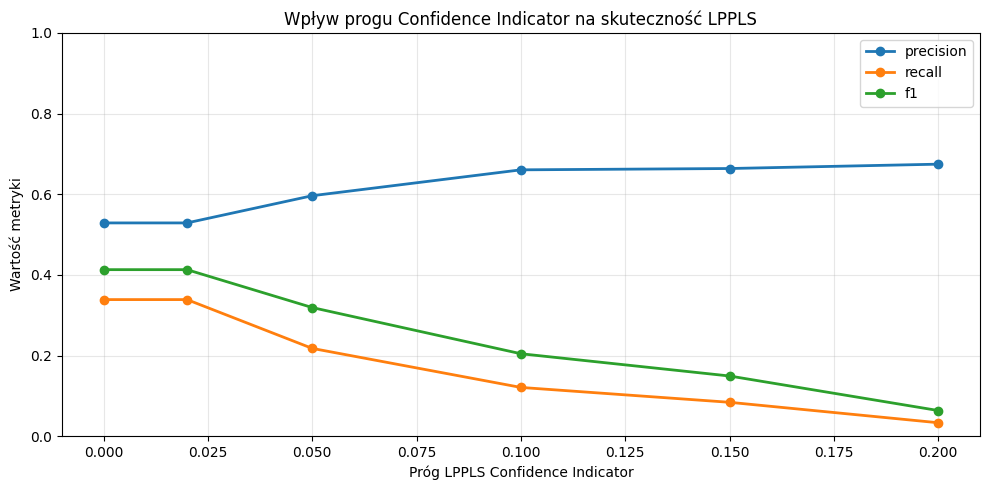

In [6]:

fig, ax = plt.subplots(figsize=(10, 5))

for metric in ["precision", "recall", "f1"]:

    ax.plot(
        summary["threshold"],
        summary[metric],
        marker="o",
        linewidth=2,
        label=metric
    )

ax.set_xlabel("Próg LPPLS Confidence Indicator")
ax.set_ylabel("Wartość metryki")
ax.set_title(
    "Wpływ progu Confidence Indicator na skuteczność LPPLS"
)
ax.set_ylim(0, 1)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()

plt.savefig(
    OUTPUT / "04_precision_recall_f1_vs_prog.png",
    dpi=200
)

plt.show()


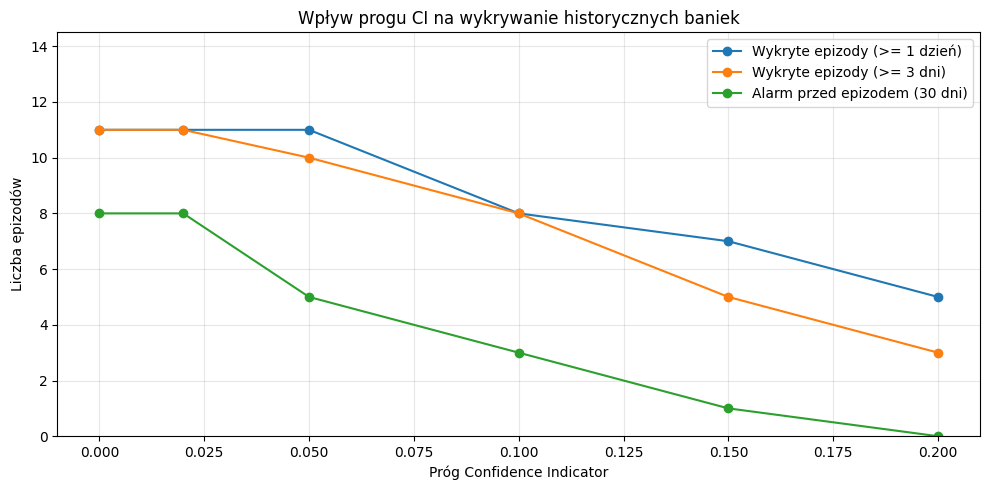

In [7]:

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    episode_summary["threshold"],
    episode_summary["detected_1_day"],
    marker="o",
    label="Wykryte epizody (>= 1 dzień)"
)

ax.plot(
    episode_summary["threshold"],
    episode_summary["detected_3_days"],
    marker="o",
    label="Wykryte epizody (>= 3 dni)"
)

ax.plot(
    episode_summary["threshold"],
    episode_summary["episodes_with_prewarning"],
    marker="o",
    label="Alarm przed epizodem (30 dni)"
)

ax.set_xlabel("Próg Confidence Indicator")
ax.set_ylabel("Liczba epizodów")
ax.set_title(
    "Wpływ progu CI na wykrywanie historycznych baniek"
)
ax.set_ylim(0, 14.5)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()

plt.savefig(
    OUTPUT / "05_wykryte_epizody_vs_prog.png",
    dpi=200
)

plt.show()


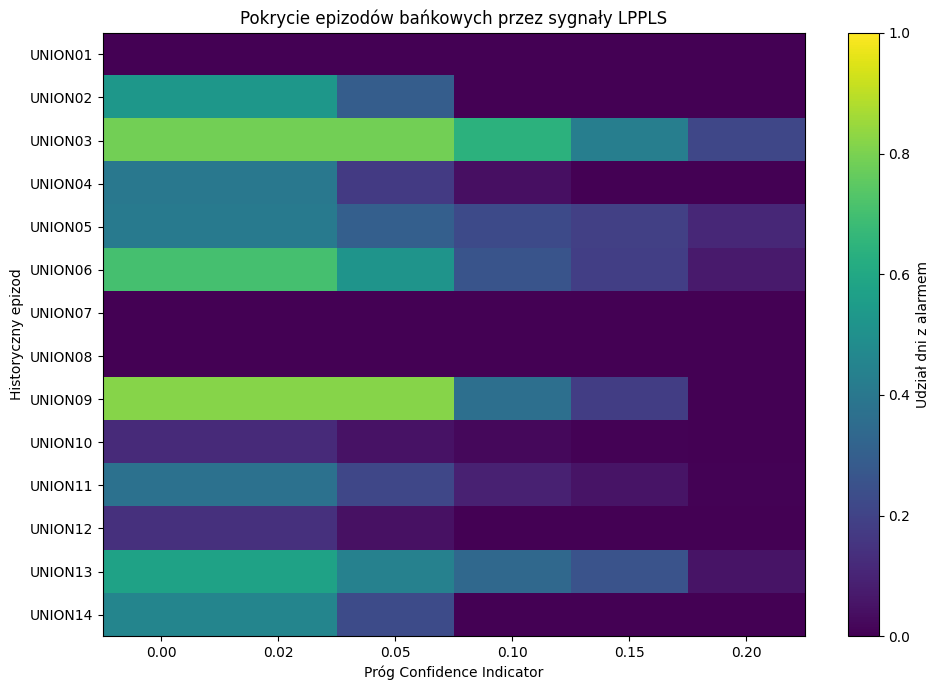

In [8]:

pivot = episode_details.pivot(
    index="bubble_id",
    columns="threshold",
    values="coverage"
)

fig, ax = plt.subplots(figsize=(10, 7))

im = ax.imshow(
    pivot.to_numpy(),
    aspect="auto",
    vmin=0,
    vmax=1
)

ax.set_xticks(
    range(len(pivot.columns)),
    [f"{t:.2f}" for t in pivot.columns]
)

ax.set_yticks(
    range(len(pivot.index)),
    pivot.index
)

ax.set_xlabel("Próg Confidence Indicator")
ax.set_ylabel("Historyczny epizod")
ax.set_title(
    "Pokrycie epizodów bańkowych przez sygnały LPPLS"
)

fig.colorbar(
    im,
    ax=ax,
    label="Udział dni z alarmem"
)

plt.tight_layout()

plt.savefig(
    OUTPUT / "06_mapa_pokrycia_epizodow.png",
    dpi=200
)

plt.show()
